# 2. Operator experiments (JPM, paper 1)

Everything in *Learning Time-Inhomogeneous Markov Dynamics in Financial Time Series via Neural
Parameterization* except the volatility analysis (notebook 3).

- A. sparsity of the empirical counts
- B. Chapman-Kolmogorov check: direct h-step operator vs product of 1-step operators
- C. operator diagnostics over time (Dobrushin, row heterogeneity, row entropy)
- D. calibration of the negative-return event
- E. 3 seeds + block bootstrap, main results table
- F. entropy floor (MIR)
- G. learning curves on train prefixes
- H. depth ablation (1 vs 5 hidden layers, same parameter count)
- I. generalization gap
- J. feature-count ablation

Weights from the run behind the paper are in `results/single_asset/paper_run/cache`, so this notebook only
trains what is missing and runs on a CPU in a few minutes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks
from sklearn.feature_selection import mutual_info_classif

from markov.data import load_jpm, returns, splits_by_horizon, standardize, return_states, forward_labels, quantile_edges, label_sigma
from markov.models import make_model, count_params, shallow_width
from markov.train import loaders, dataset, fit, operators
from markov.metrics import (evaluate, predict, baselines, label_sparsity, transition_sparsity, compose, ck_errors,
                            dobrushin, row_heterogeneity, row_entropy, spectral_proxy, pit, ece, brier,
                            entropy_floor, mir, spectral_norm_product, block_bootstrap)
from markov.plots import save, over_time, heatmap
from torch.utils.data import DataLoader

HORIZONS = [1, 2, 5, 10]
N_BINS = [10, 20, 35, 55]
KEY = [(1, 55), (10, 55)]
SEEDS = [42, 7, 123]
SEED = 42
ALPHAS = [1e-6, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 5.0, 10.0]
TAUS = [10, 50, 100, 200, 500, 1000]
OUT = ROOT / "results/single_asset/paper_run"
CACHE = OUT / "cache"
FIG = OUT / "figures"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
prices, F, cols = load_jpm()
sp = splits_by_horizon(len(prices) - 1, HORIZONS)
F = standardize(F, sp[1]["idx_train"])
X, n_x, edges_x = return_states(prices, 55, len(sp[1]["idx_train"]))
configs = forward_labels(prices, sp, N_BINS)
# CK task: the label is the state h days ahead, so every operator is 55 x 55
ck_labels = {h: X[h:] for h in HORIZONS}
grid = pd.read_csv(ROOT / "results/single_asset/grid/grid_results.csv")
print(f"{len(prices)} days, {F.shape[1]} features, {n_x} states")

2369 days, 194 features, 55 states


## A. Sparsity of the empirical counts

In [3]:
rows = []
for (h, N), c in configs.items():
    s = label_sparsity(c["y_all"][c["idx_train"]], c["N_actual"])
    rows.append({"h": h, "N": N, "N_actual": c["N_actual"], "n_train": len(c["idx_train"]), "effective_bins": s["effective"],
                 **{f"frac_below_{k}": v for k, v in s["frac_below"].items()}})
pd.DataFrame(rows).to_csv(OUT / "degeneracy_label_table.csv", index=False)

METRICS = ["frac_cells_zero", "frac_cells_lt5", "frac_cells_lt10", "frac_rows_lt5", "frac_rows_lt10",
           "median_nonzero_per_row", "p90_nonzero_per_row", "median_row_entropy_empirical", "median_row_maxprob_empirical"]
sparsity, rows = {}, []
for (h, N), c in configs.items():
    tr = c["idx_train"]
    s = transition_sparsity(X[tr], c["y_all"][tr], n_x, c["N_actual"])
    sparsity[(h, N)] = s
    rows.append({"config_type": "cumulative", "h": h, "N": N, "N_actual": c["N_actual"], **{m: s[m] for m in METRICS}})
for h in HORIZONS:
    tr = sp[h]["idx_train"]
    s = transition_sparsity(X[tr], ck_labels[h][tr], n_x, n_x)
    rows.append({"config_type": "ck", "h": h, "N": n_x, "N_actual": n_x, **{m: s[m] for m in METRICS}})
df_sparsity = pd.DataFrame(rows)
df_sparsity.to_csv(OUT / "degeneracy_transition_table.csv", index=False)
print(df_sparsity[["config_type", "h", "N", "frac_cells_zero", "frac_cells_lt5", "median_nonzero_per_row"]].to_string(index=False))

config_type  h  N  frac_cells_zero  frac_cells_lt5  median_nonzero_per_row
 cumulative  1 10         0.056364        0.827273                    10.0
 cumulative  1 20         0.224545        0.980000                    16.0
 cumulative  1 35         0.436364        0.995844                    20.0
 cumulative  1 55         0.579504        0.998678                    23.0
 cumulative  2 10         0.034545        0.807273                    10.0
 cumulative  2 20         0.213636        0.976364                    16.0
 cumulative  2 35         0.423377        0.996883                    20.0
 cumulative  2 55         0.582149        0.999339                    23.0
 cumulative  5 10         0.049091        0.827273                    10.0
 cumulative  5 20         0.218182        0.977273                    16.0
 cumulative  5 35         0.423896        0.996883                    20.0
 cumulative  5 55         0.582479        0.999669                    23.0
 cumulative 10 10        

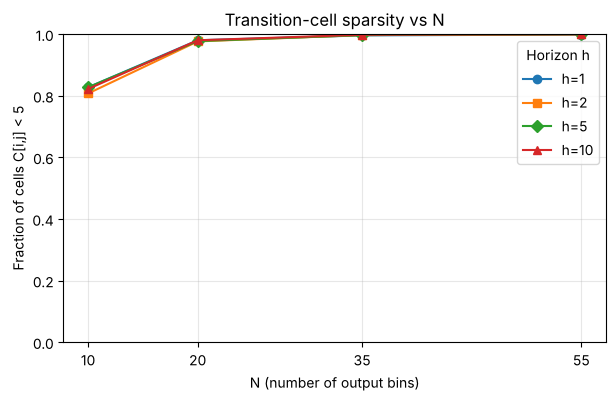

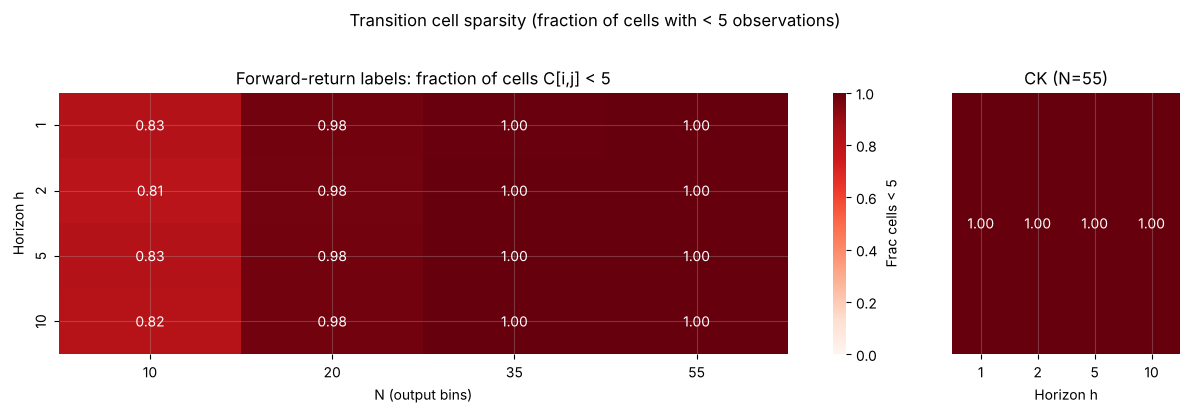

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for h, m in zip(HORIZONS, "osD^"):
    ax.plot(N_BINS, [sparsity[(h, N)]["frac_cells_lt5"] for N in N_BINS], marker=m, label=f"h={h}")
ax.set(xlabel="N (number of output bins)", ylabel="Fraction of cells C[i,j] < 5", ylim=(0, 1), xticks=N_BINS,
       title="Transition-cell sparsity vs N")
ax.legend(title="Horizon h")
save(fig, FIG / "sparsity_vs_N")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [4, 1]})
cum = df_sparsity[df_sparsity.config_type == "cumulative"].pivot(index="h", columns="N", values="frac_cells_lt5")
sns.heatmap(cum, ax=axes[0], annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "Frac cells < 5"})
axes[0].set(title="Forward-return labels: fraction of cells C[i,j] < 5", xlabel="N (output bins)", ylabel="Horizon h")
ck = df_sparsity[df_sparsity.config_type == "ck"].set_index("h")["frac_cells_lt5"].to_frame().T
sns.heatmap(ck, ax=axes[1], annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, cbar=False)
axes[1].set(title="CK (N=55)", xlabel="Horizon h", ylabel="", yticks=[])
fig.suptitle("Transition cell sparsity (fraction of cells with < 5 observations)", y=1.02)
fig.tight_layout()
save(fig, FIG / "transition_sparsity_heatmap")
plt.show()

## B. Chapman-Kolmogorov check

Train one net per horizon to predict X_{t+h} directly, then compare A_t^(h) with A_t^(1) A_{t+1}^(1) ... A_{t+h-1}^(1)
on the test period. Row KL is weighted by how often each state appears in train.

In [5]:
A = {}
for h in HORIZONS:
    s = sp[h]
    tr, va, te = loaders(F, X, ck_labels[h], s)
    # soft-label width: h-day return bins on the CK train window, relative to the 1-day state bins
    _, edges_h = quantile_edges(returns(prices, h)[s["idx_train"]], n_x)
    sigma = label_sigma(edges_h, edges_x)
    for kind in ["state_cond", "state_free"]:
        torch.manual_seed(SEED)
        model = make_model(kind, F.shape[1], n_x, n_x)
        model, _ = fit(model, CACHE / f"ck_{kind}_h{h}_seed{SEED}.pt", tr, va, n_x, sigma, DEVICE, verbose=True)
        A[(kind, h)] = operators(model, F, np.arange(s["T"]), n_x, n_x, DEVICE, state_free=kind == "state_free")
print("operators:", {k: v.shape for k, v in A.items()})

operators: {('state_cond', 1): (2367, 55, 55), ('state_free', 1): (2367, 55, 55), ('state_cond', 2): (2366, 55, 55), ('state_free', 2): (2366, 55, 55), ('state_cond', 5): (2363, 55, 55), ('state_free', 5): (2363, 55, 55), ('state_cond', 10): (2358, 55, 55), ('state_free', 10): (2358, 55, 55)}


In [6]:
ck_rows, ck_series = [], {}
for h in HORIZONS:
    s = sp[h]
    tr, te0, T = s["idx_train"], s["idx_test"][0], s["T"]
    weights = np.bincount(X[tr], minlength=n_x).astype(np.float64)
    ck_cfg = {**s, "y_all": ck_labels[h], "N_actual": n_x}
    A_bk = baselines(ck_cfg, X, n_x, ALPHAS, TAUS)["backoff"]["matrix"]
    cands = {"state_cond": A[("state_cond", h)], "state_free": A[("state_free", h)], "backoff_ck": np.tile(A_bk[None], (T, 1, 1))}
    A1 = {"state_cond": A[("state_cond", 1)], "state_free": A[("state_free", 1)], "backoff_ck": cands["backoff_ck"]}
    for name, Ah in cands.items():
        if h == 1:
            ck_rows.append({"model": name, "h": h, "mean_kl": 0.0, "mean_tv": 0.0, "frobenius": 0.0, "note": "h=1: trivial"})
            continue
        # direct operator on the test window vs product of the next h one-step operators
        e = ck_errors(Ah[te0:T - h + 1], compose(A1[name][te0:T], h), weights)
        ck_series[(name, h)] = e["per_time_kl"]
        ck_rows.append({"model": name, "h": h, "mean_kl": e["mean_kl"], "mean_tv": e["mean_tv"], "frobenius": e["frobenius"]})
df_ck = pd.DataFrame(ck_rows)
df_ck.to_csv(OUT / "ck_table.csv", index=False)
print(df_ck.round(4).to_string(index=False))

     model  h  mean_kl  mean_tv  frobenius         note
state_cond  1   0.0000   0.0000     0.0000 h=1: trivial
state_free  1   0.0000   0.0000     0.0000 h=1: trivial
backoff_ck  1   0.0000   0.0000     0.0000 h=1: trivial
state_cond  2   0.1518   0.1884     0.4400          NaN
state_free  2   0.0299   0.0868     0.2253          NaN
backoff_ck  2   0.0106   0.0637     0.1502          NaN
state_cond  5   0.1403   0.2060     0.4880          NaN
state_free  5   0.0225   0.0854     0.2119          NaN
backoff_ck  5   0.0029   0.0328     0.0767          NaN
state_cond 10   0.1517   0.1930     0.4477          NaN
state_free 10   0.0295   0.0847     0.2210          NaN
backoff_ck 10   0.0001   0.0060     0.0140          NaN


In [7]:
# not a CK test: does a single average one-step operator raised to the h-th power match the direct h-step one?
rows = []
A_avg = A[("state_cond", 1)][sp[1]["idx_train"]].mean(axis=0)
for h in HORIZONS[1:]:
    Ah = A[("state_cond", h)][sp[h]["idx_test"]]
    e = ck_errors(Ah, np.tile(np.linalg.matrix_power(A_avg, h)[None], (len(Ah), 1, 1)))
    rows.append({"h": h, "mean_kl": e["mean_kl"], "note": "average A^(1) raised to the power h"})
pd.DataFrame(rows).to_csv(OUT / "stationarity_probe.csv", index=False)
print(pd.DataFrame(rows).round(4))

    h  mean_kl                                 note
0   2   0.0030  average A^(1) raised to the power h
1   5   0.0488  average A^(1) raised to the power h
2  10   0.0050  average A^(1) raised to the power h


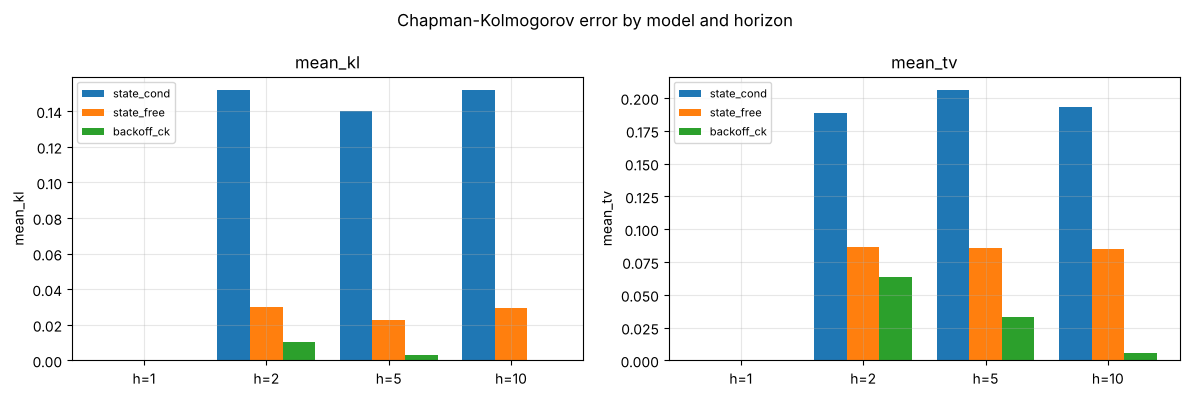

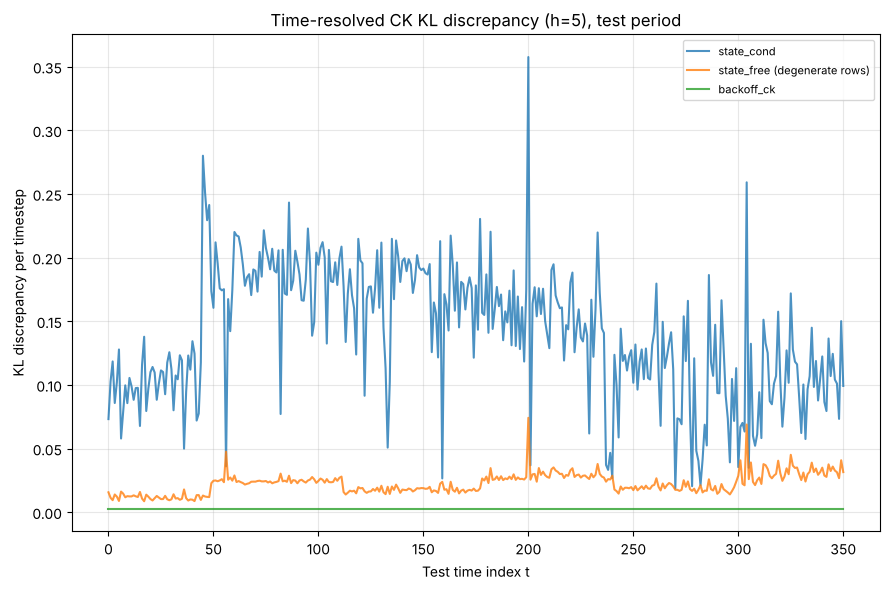

In [8]:
models = df_ck.model.unique()
hs = sorted(df_ck.h.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["mean_kl", "mean_tv"]):
    for i, m in enumerate(models):
        sub = df_ck[df_ck.model == m].set_index("h")[metric]
        ax.bar(np.arange(len(hs)) + (i - 1) * 0.8 / 3, [sub[h] for h in hs], 0.8 / 3, label=m)
    ax.set(xticks=np.arange(len(hs)), xticklabels=[f"h={h}" for h in hs], ylabel=metric, title=metric)
    ax.legend(fontsize=8)
fig.suptitle("Chapman-Kolmogorov error by model and horizon")
fig.tight_layout()
save(fig, FIG / "ck_error_summary")
plt.show()

for h in HORIZONS[1:]:
    fig, ax = plt.subplots(figsize=(9, 6))
    for (name, hh), s in ck_series.items():
        if hh == h:
            ax.plot(s, label=name + (" (degenerate rows)" if "state_free" in name else ""), alpha=0.8)
    ax.set(title=f"Time-resolved CK KL discrepancy (h={h}), test period", xlabel="Test time index t",
           ylabel="KL discrepancy per timestep")
    ax.legend(fontsize=8)
    fig.tight_layout()
    save(fig, FIG / f"ck_error_time_series_h{h}")
    plt.show() if h == 5 else plt.close(fig)

## C. Operator diagnostics over the full series (1-step CK models)

In [9]:
diag = {}
for kind in ["state_cond", "state_free"]:
    A1 = A[(kind, 1)]
    diag[kind] = {"dobrushin": dobrushin(A1), "row_heterogeneity": row_heterogeneity(A1),
                  "row_entropy": row_entropy(A1), "spectral_proxy": spectral_proxy(A1)}
    print(kind, {k: (round(float(v.mean()), 4), round(float(v.max()), 4)) for k, v in diag[kind].items()})
pd.DataFrame({f"{k}_{m}": v for k, d in diag.items() for m, v in d.items()}).to_csv(OUT / "operator_diagnostics.csv", index_label="t")

state_cond {'dobrushin': (0.0294, 0.0567), 'row_heterogeneity': (0.0073, 0.0139), 'row_entropy': (3.926, 4.0061), 'spectral_proxy': (0.0138, 0.0318)}


state_free {'dobrushin': (0.0, 0.0), 'row_heterogeneity': (0.0, 0.0), 'row_entropy': (3.952, 4.0062), 'spectral_proxy': (0.0, 0.0)}


regime windows: [(np.int64(193), np.int64(223), 't=208'), (np.int64(238), np.int64(268), 't=253'), (np.int64(282), np.int64(312), 't=297')]


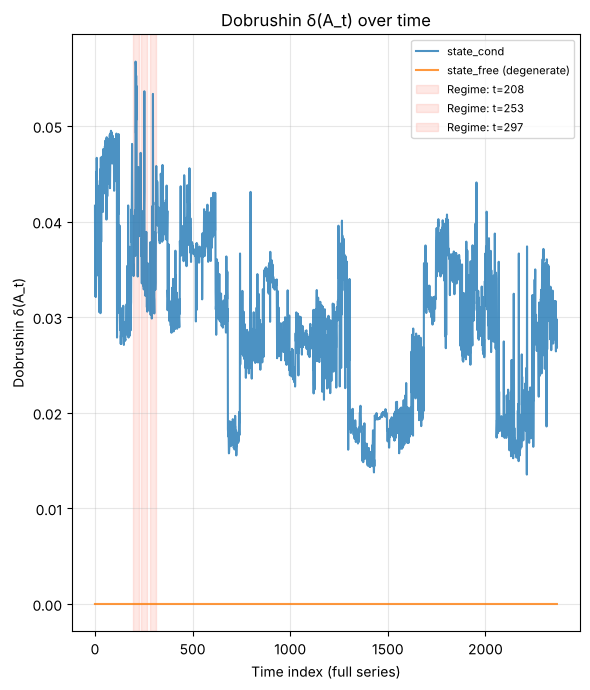

In [10]:
# regime windows: +-15 days around the 3 largest Dobrushin peaks of the state-conditioned model
d = diag["state_cond"]["dobrushin"]
peaks, _ = find_peaks(d, distance=30)
peaks = sorted(peaks[np.argsort(d[peaks])[::-1][:3]])
windows = [(max(0, p - 15), min(len(d) - 1, p + 15), f"t={p}") for p in peaks]
print("regime windows:", windows)

for kind in ["state_cond", "state_free"]:
    for p in peaks:
        heatmap(A[(kind, 1)][p], f"A_t Transition Matrix t{p}\n(model: {kind})", FIG / f"At_heatmap_{kind}_t{p}")
        plt.close("all")

labels = {"dobrushin": "Dobrushin δ(A_t)", "row_heterogeneity": "Row heterogeneity", "row_entropy": "Row entropy H(A_t)",
          "spectral_proxy": "Spectral mixing proxy"}
stems = {"dobrushin": "dobrushin_over_time", "row_heterogeneity": "row_heterogeneity_over_time",
         "row_entropy": "row_entropy_over_time", "spectral_proxy": "spectral_proxy_over_time"}
for m in labels:
    over_time({k: diag[k][m] for k in diag}, labels[m], FIG / stems[m], windows, figsize=(6, 7), title=f"{labels[m]} over time")
    plt.show() if m == "dobrushin" else plt.close("all")

## D. Calibration of P(negative return) at h=1 and h=10, N=55

     model  h  N  ece_neg_return  brier_neg_return  n_test
   backoff  1 55          0.0808            0.2485     356
state_cond  1 55          0.0793            0.2468     356
state_free  1 55          0.0948            0.2510     356
   backoff 10 55          0.1096            0.2479     354
state_cond 10 55          0.1114            0.2482     354
state_free 10 55          0.1102            0.2484     354


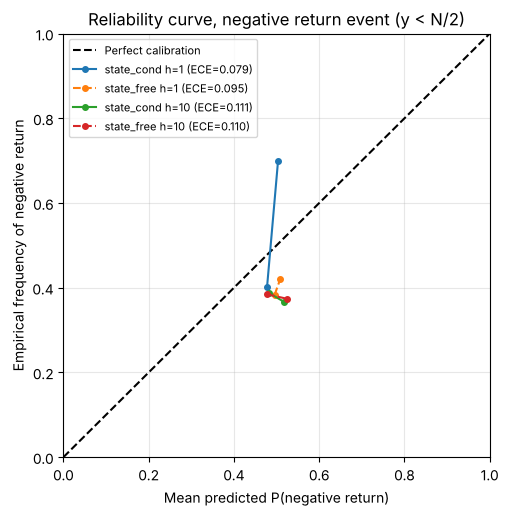

In [11]:
calib_rows, curves = [], []
for h, N in KEY:
    c = configs[(h, N)]
    n = c["N_actual"]
    tr, va, te = loaders(F, X, c["y_all"], c)
    y_te = c["y_all"][c["idx_test"]]
    neg = lambda y, n=n: y < n // 2
    for kind in ["state_cond", "state_free"]:
        torch.manual_seed(SEED)
        model, _ = fit(make_model(kind, F.shape[1], n_x, n), CACHE / f"calib_{kind}_h{h}_N{N}_seed{SEED}.pt",
                       tr, va, n, c["sigma"], DEVICE)
        probs = predict(model, te, DEVICE)
        e, conf, acc = ece(probs, y_te, neg)
        calib_rows.append({"model": kind, "h": h, "N": N, "ece_neg_return": e, "brier_neg_return": brier(probs, y_te, neg),
                           "n_test": len(y_te)})
        curves.append((f"{kind} h={h}", conf, acc, e))
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.hist(pit(probs, y_te), bins=20, range=(0, 1), density=True, color="steelblue", edgecolor="white")
        ax.axhline(1.0, color="red", ls="--", label="Uniform (ideal)")
        ax.set(xlabel="PIT value", ylabel="Density", title=f"PIT histogram: {kind} h={h} N={N}", xlim=(0, 1))
        ax.legend()
        save(fig, FIG / f"pit_histogram_{kind}_h{h}_N{N}")
        plt.close(fig)
    P_bk = baselines(c, X, n_x, ALPHAS, TAUS)["backoff"]["matrix"]
    probs = P_bk[X[c["idx_test"]]]
    calib_rows.append({"model": "backoff", "h": h, "N": N, "ece_neg_return": ece(probs, y_te, neg)[0],
                       "brier_neg_return": brier(probs, y_te, neg), "n_test": len(y_te)})
df_calib = pd.DataFrame(calib_rows).sort_values(["h", "N", "model"]).reset_index(drop=True)
df_calib.to_csv(OUT / "calibration_table.csv", index=False)
print(df_calib.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for (label, conf, acc, e), color, ls in zip(curves, ["C0", "C1", "C2", "C3"], ["-", "--", "-", "--"]):
    ax.plot(conf[conf > 0], acc[conf > 0], marker="o", ms=4, color=color, ls=ls, label=f"{label} (ECE={e:.3f})")
ax.set(xlabel="Mean predicted P(negative return)", ylabel="Empirical frequency of negative return",
       title="Reliability curve, negative return event (y < N/2)", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8, loc="upper left")
save(fig, FIG / "reliability_neg_return")
plt.show()

## E. Three seeds, block bootstrap and the main results table

Non-key configs take the single-seed grid run (notebook 1). The two key configs use the mean over 3 seeds,
and their CI comes from a 21-day block bootstrap of the seed-averaged per-day log-likelihood.

In [12]:
seed_ll = {}
for h, N in KEY:
    c = configs[(h, N)]
    n = c["N_actual"]
    tr, va, te = loaders(F, X, c["y_all"], c)
    for seed in SEEDS:
        for kind in ["state_cond", "state_free"]:
            torch.manual_seed(seed)
            model, _ = fit(make_model(kind, F.shape[1], n_x, n), CACHE / f"seed_{kind}_h{h}_N{N}_seed{seed}.pt",
                           tr, va, n, c["sigma"], DEVICE)
            seed_ll[(h, N, kind, seed)] = evaluate(model, te, n, DEVICE)["loglik"]
print(pd.DataFrame([{"h": k[0], "kind": k[2], "seed": k[3], "test_ll": v.mean()} for k, v in seed_ll.items()])
      .groupby(["h", "kind"]).test_ll.agg(["mean", "std"]).round(4))

                 mean     std
h  kind                      
1  state_cond -4.0402  0.0284
   state_free -4.0481  0.0438
10 state_cond -4.0019  0.0124
   state_free -3.9907  0.0054


In [13]:
main = grid[["h", "N", "model", "test_ll", "val_ll", "accuracy"]].copy()
main["ci_lower"], main["ci_upper"] = np.nan, np.nan
for h, N in KEY:
    for kind in ["state_cond", "state_free"]:
        ll = np.stack([seed_ll[(h, N, kind, s)] for s in SEEDS]).mean(axis=0)
        mean, lo, hi = block_bootstrap(ll, 21, 500, seed=SEED)
        i = main.index[(main.h == h) & (main.N == N) & (main.model == f"{kind}_nn")]
        main.loc[i, ["test_ll", "ci_lower", "ci_upper"]] = mean, lo, hi
marg = main[main.model == "marginal"].set_index(["h", "N"]).test_ll
main["delta_ll"] = main.test_ll - [marg[(h, N)] for h, N in zip(main.h, main.N)]
main["delta_ci_lower"] = main.ci_lower - [marg[(h, N)] for h, N in zip(main.h, main.N)]
main["delta_ci_upper"] = main.ci_upper - [marg[(h, N)] for h, N in zip(main.h, main.N)]
main = main.sort_values(["h", "N", "model"]).reset_index(drop=True)
main.to_csv(OUT / "main_results_table.csv", index=False)
print(main.pivot_table(index="model", columns=["h", "N"], values="delta_ll").round(4).to_string())
print()
print(main[[(h, N) in KEY for h, N in zip(main.h, main.N)]][["h", "N", "model", "delta_ll", "delta_ci_lower", "delta_ci_upper"]]
      .round(4).to_string(index=False))

h                  1                               2                               5                               10                        
N                  10      20      35      55      10      20      35      55      10      20      35      55      10      20      35      55
model                                                                                                                                        
additive       0.0037 -0.0027 -0.0002  0.0074  0.0024 -0.0029 -0.0025 -0.0033 -0.0083 -0.0000  0.0023 -0.0031  0.0006 -0.0082 -0.0004 -0.0003
backoff        0.0016  0.0001  0.0001  0.0003  0.0034  0.0000 -0.0010 -0.0020 -0.0000  0.0006  0.0002 -0.0025  0.0003 -0.0001  0.0001  0.0001
marginal       0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
state_cond_nn -0.0012 -0.0615 -0.0161 -0.0328 -0.0009 -0.0853 -0.0290 -0.0360 -0.0049 -0.0922 -0.1175 -0.0085 -0.0051  0.0022 -0.0284  0.0055
state_

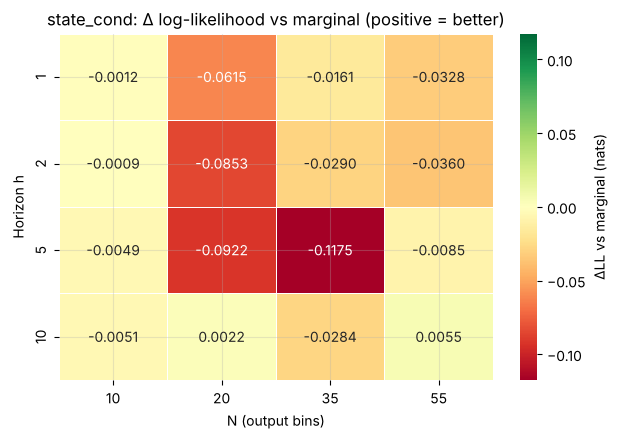

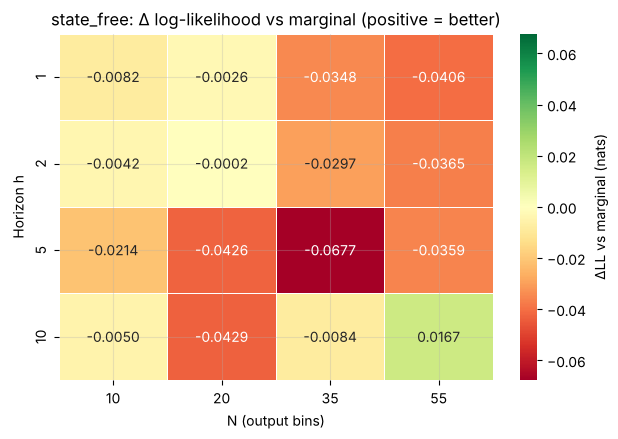

In [14]:
for kind in ["state_cond", "state_free"]:
    pivot = main[main.model == f"{kind}_nn"].pivot(index="h", columns="N", values="delta_ll")
    pivot.to_csv(OUT / f"main_results_heatmap_values_{kind}.csv")
    v = max(float(np.abs(pivot.values).max()), 1e-4)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".4f", cmap="RdYlGn", center=0, vmin=-v, vmax=v, linewidths=0.5,
                cbar_kws={"label": "ΔLL vs marginal (nats)"})
    ax.set(title=f"{kind}: Δ log-likelihood vs marginal (positive = better)", xlabel="N (output bins)", ylabel="Horizon h")
    save(fig, FIG / f"main_results_heatmap_{kind}")
    plt.show()

## F. Entropy floor

H_irr is the expected row entropy of the empirical transition matrix on train, the NLL an oracle with the
empirical P(Y|X) would get. MIR = (H_irr - NLL) / H_irr, negative means worse than that floor.

In [15]:
rows = []
for (h, N), s in sparsity.items():
    h_irr = entropy_floor(s["C"])
    c = configs[(h, N)]
    p = np.bincount(c["y_all"][c["idx_train"]], minlength=c["N_actual"]).astype(np.float64)
    p = (p + 1e-12) / (p.sum() + c["N_actual"] * 1e-12)
    for _, r in main[(main.h == h) & (main.N == N)].iterrows():
        rows.append({"h": h, "N": N, "model": r.model, "test_ll": r.test_ll, "nll_model": -r.test_ll, "H_irr": h_irr,
                     "H_marginal": float(-(p * np.log(p)).sum()), "MIR": mir(-r.test_ll, h_irr)})
df_mir = pd.DataFrame(rows).sort_values(["h", "N", "model"]).reset_index(drop=True)
df_mir.to_csv(OUT / "mir_table.csv", index=False)
print(df_mir[[(h, N) in KEY for h, N in zip(df_mir.h, df_mir.N)]].round(4).to_string(index=False))

 h  N         model  test_ll  nll_model  H_irr  H_marginal     MIR
 1 55      additive  -4.0000     4.0000 3.0543      4.0073 -0.3096
 1 55       backoff  -4.0072     4.0072 3.0543      4.0073 -0.3120
 1 55      marginal  -4.0075     4.0075 3.0543      4.0073 -0.3121
 1 55 state_cond_nn  -4.0402     4.0402 3.0543      4.0073 -0.3228
 1 55 state_free_nn  -4.0481     4.0481 3.0543      4.0073 -0.3253
10 55      additive  -4.0076     4.0076 3.0893      4.0073 -0.2973
10 55       backoff  -4.0073     4.0073 3.0893      4.0073 -0.2972
10 55      marginal  -4.0073     4.0073 3.0893      4.0073 -0.2972
10 55 state_cond_nn  -4.0019     4.0019 3.0893      4.0073 -0.2954
10 55 state_free_nn  -3.9907     3.9907 3.0893      4.0073 -0.2918


## G. Learning curves on chronological train prefixes

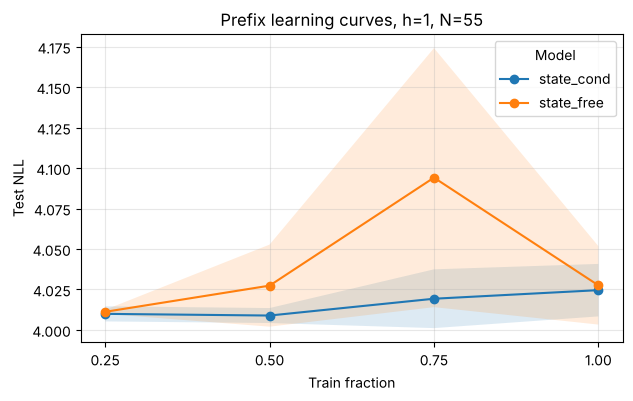

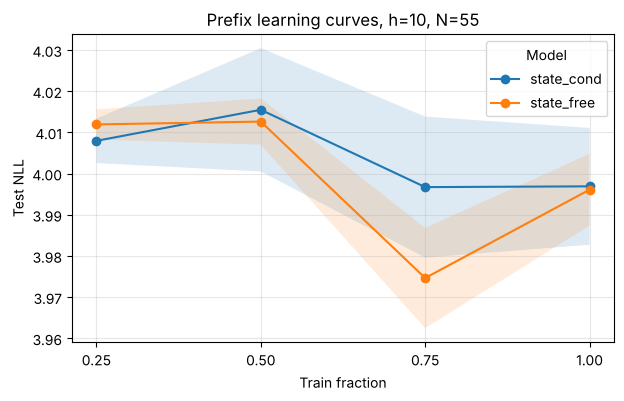

In [16]:
rows = []
for h, N in KEY:
    c = configs[(h, N)]
    n = c["N_actual"]
    _, va, te = loaders(F, X, c["y_all"], c)
    for frac in [0.25, 0.50, 0.75, 1.00]:
        prefix = c["idx_train"][: max(1, int(frac * len(c["idx_train"])))]
        tr = DataLoader(dataset(F, X, c["y_all"], prefix), batch_size=256, shuffle=True)
        for kind in ["state_cond", "state_free"]:
            for seed in SEEDS:
                torch.manual_seed(seed)
                model, _ = fit(make_model(kind, F.shape[1], n_x, n),
                               CACHE / f"lc_{kind}_h{h}_N{N}_frac{int(frac * 100)}_seed{seed}.pt", tr, va, n, c["sigma"], DEVICE)
                rows.append({"model": kind, "h": h, "N": N, "train_frac": frac, "seed": seed,
                             "nll_val": -evaluate(model, va, n, DEVICE)["mean_ll"],
                             "nll_test": -evaluate(model, te, n, DEVICE)["mean_ll"]})
df_lc = pd.DataFrame(rows)
df_lc.to_csv(OUT / "learning_curve_table.csv", index=False)

for h, N in KEY:
    fig, ax = plt.subplots(figsize=(7, 4))
    for kind, grp in df_lc[(df_lc.h == h) & (df_lc.N == N)].groupby("model"):
        g = grp.groupby("train_frac").nll_test.agg(["mean", "std"])
        ax.plot(g.index, g["mean"], marker="o", label=kind)
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], alpha=0.15)
    ax.set(xlabel="Train fraction", ylabel="Test NLL", title=f"Prefix learning curves, h={h}, N={N}", xticks=[0.25, 0.5, 0.75, 1.0])
    ax.legend(title="Model")
    save(fig, FIG / f"learning_curve_nll_{h}_{N}")
    plt.show()

## H. Depth ablation: 1 hidden layer vs 5, matched on parameter count

In [17]:
DEEP = (64, 128, 256, 128, 64)
rows = []
for h, N in KEY:
    c = configs[(h, N)]
    n = c["N_actual"]
    tr, va, te = loaders(F, X, c["y_all"], c)
    for kind in ["state_cond", "state_free"]:
        kw = {"kind": kind, "n_feat": F.shape[1], "n_states": n_x, "n_out": n}
        width = shallow_width(count_params(make_model(**kw)), **kw)
        for arch, hidden in [("deep", DEEP), ("shallow", (width,))]:
            for seed in SEEDS:
                torch.manual_seed(seed)
                model, _ = fit(make_model(hidden=hidden, **kw), CACHE / f"depth_{arch}_{kind}_h{h}_N{N}_seed{seed}.pt",
                               tr, va, n, c["sigma"], DEVICE)
                rows.append({"model": kind, "arch": arch, "h": h, "N": N, "seed": seed,
                             "nll_test": -evaluate(model, te, n, DEVICE)["mean_ll"], "n_params": count_params(model)})
df_da = pd.DataFrame(rows)
shallow = df_da[df_da.arch == "shallow"].set_index(["model", "h", "N", "seed"]).nll_test
df_da["delta_nll_vs_shallow"] = df_da.nll_test - [shallow[k] for k in zip(df_da.model, df_da.h, df_da.N, df_da.seed)]
df_da = df_da.sort_values(["h", "N", "model", "arch", "seed"]).reset_index(drop=True)
df_da.to_csv(OUT / "depth_ablation_table.csv", index=False)
print(df_da.groupby(["h", "model", "arch"])[["nll_test", "n_params"]].mean().round(4))

for h, N in KEY:
    agg = df_da[(df_da.h == h) & (df_da.N == N)].groupby(["model", "arch"]).nll_test.agg(["mean", "std"])
    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (arch, color) in enumerate([("shallow", "#aec7e8"), ("deep", "#1f77b4")]):
        ax.bar(np.arange(2) + (i - 0.5) * 0.35, [agg.loc[(m, arch), "mean"] for m in ["state_cond", "state_free"]], 0.35,
               yerr=[agg.loc[(m, arch), "std"] for m in ["state_cond", "state_free"]], capsize=4, label=arch, color=color)
    ax.set(xticks=range(2), xticklabels=["state_cond", "state_free"], ylabel="Test NLL (nats)", title=f"Depth ablation, h={h}, N={N}")
    ax.legend(title="Architecture")
    save(fig, FIG / f"depth_ablation_bar_{h}_{N}")
    plt.close(fig)

                       nll_test  n_params
h  model      arch                       
1  state_cond deep       4.0246  102071.0
              shallow    4.3591  101925.0
   state_free deep       4.0276   98551.0
              shallow    4.3365   98555.0
10 state_cond deep       3.9969  102071.0
              shallow    4.3430  101925.0
   state_free deep       3.9961   98551.0
              shallow    4.2463   98555.0


## I. Generalization gap (h=1, N=55)

In [18]:
c = configs[(1, 55)]
tr, va, _ = loaders(F, X, c["y_all"], c)
rows = []
for kind in ["state_cond", "state_free"]:
    torch.manual_seed(SEED)
    path, hist_path = CACHE / f"gengap_{kind}_h1_N55_seed42.pt", CACHE / f"gengap_hist_{kind}_h1_N55_seed42.npy"
    model, hist = fit(make_model(kind, F.shape[1], n_x, 55), path, tr, va, 55, c["sigma"], DEVICE, log_nll=True)
    if hist is not None:
        np.save(hist_path, {k: hist[k] for k in ["train_nll", "val_nll"]})
    hist = np.load(hist_path, allow_pickle=True).item()
    spec = spectral_norm_product(model)
    for ep, (a, b) in enumerate(zip(hist["train_nll"], hist["val_nll"])):
        rows.append({"model": kind, "epoch": ep + 1, "train_nll": a, "val_nll": b, "gap": b - a, "spec_prod": spec})
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(hist["train_nll"], label="Train NLL")
    ax.plot(hist["val_nll"], label="Val NLL")
    ax.set(xlabel="Epoch", ylabel="NLL (nats)", title=f"Train vs val NLL per epoch, {kind}")
    ax.legend()
    save(fig, FIG / f"gengap_{kind}_h1_N55_nll_curves")
    plt.close(fig)
df_gg = pd.DataFrame(rows)
df_gg.to_csv(OUT / "generalization_gap_table.csv", index=False)
print(df_gg.groupby("model").agg(mean_gap=("gap", "mean"), max_gap=("gap", "max"), spec_prod=("spec_prod", "first")).round(4))

            mean_gap  max_gap  spec_prod
model                                   
state_cond    0.1431   0.2518    38.2833
state_free    0.0959   0.1344    56.6550


## J. Feature-count ablation

Keep the top-k features by mutual information with the train labels (state-conditioned net, one seed).
The ranking is saved the first time so cached weights always see the same columns. The order of features
with zero MI depends on the machine's sort, so the saved h=1 file keeps the order of the original run.

In [19]:
rows = []
for h, N in KEY:
    c = configs[(h, N)]
    n = c["N_actual"]
    rank_path = OUT / f"feature_ranking_h{h}_N{N}.csv"
    if rank_path.exists():
        ranking = pd.read_csv(rank_path).feature_index.values
    else:
        mi = mutual_info_classif(F[c["idx_train"]], c["y_all"][c["idx_train"]], random_state=SEED, n_neighbors=5)
        ranking = np.argsort(mi)[::-1]
        pd.DataFrame({"feature_index": ranking, "feature": np.array(cols)[ranking], "mi": mi[ranking]}).to_csv(rank_path, index=False)
    for k in [15, 30, 50, 194]:
        Fk = F[:, ranking[:k]]
        tr, va, te = loaders(Fk, X, c["y_all"], c)
        torch.manual_seed(SEED)
        model, _ = fit(make_model("state_cond", k, n_x, n), CACHE / f"feat_abl_n{k}_h{h}_N{N}_seed{SEED}.pt", tr, va, n, c["sigma"], DEVICE)
        train_eval = DataLoader(dataset(Fk, X, c["y_all"], c["idx_train"]), batch_size=512)
        nll = {s: -evaluate(model, l, n, DEVICE)["mean_ll"] for s, l in [("train", train_eval), ("val", va), ("test", te)]}
        rows.append({"horizon": h, "N_bins": N, "n_features": k, "train_nll": nll["train"], "val_nll": nll["val"],
                     "test_nll": nll["test"], "gen_gap": nll["test"] - nll["train"], "spectral_product": spectral_norm_product(model)})
df_fa = pd.DataFrame(rows)
df_fa.to_csv(OUT / "feature_ablation_table.csv", index=False)
print(df_fa.round(4).to_string(index=False))

for h, N in KEY:
    sub = df_fa[(df_fa.horizon == h) & (df_fa.N_bins == N)]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].plot(sub.n_features, sub.test_nll, "o-", label="test NLL")
    axes[0].plot(sub.n_features, sub.val_nll, "s--", label="val NLL")
    axes[0].legend()
    axes[1].plot(sub.n_features, sub.gen_gap, "o-", color="#d62728")
    axes[2].plot(sub.n_features, sub.spectral_product, "o-", color="#2ca02c")
    for ax, t in zip(axes, ["NLL", "Test NLL - train NLL", "Spectral norm product"]):
        ax.set(xlabel="Number of input features", title=t, xticks=sub.n_features)
    fig.suptitle(f"Feature-count ablation, h={h}, N={N}")
    fig.tight_layout()
    save(fig, FIG / f"feature_ablation_h{h}_N{N}")
    plt.close(fig)

 horizon  N_bins  n_features  train_nll  val_nll  test_nll  gen_gap  spectral_product
       1      55          15     3.9257   3.9889    4.0105   0.0848           65.0651
       1      55          30     4.0073   4.0047    4.0036  -0.0037            2.1699
       1      55          50     3.9146   3.9966    4.0289   0.1143           36.1225
       1      55         194     3.8904   3.9774    4.0191   0.1287           47.1689
      10      55          15     3.9180   3.9834    3.9892   0.0712           87.1779
      10      55          30     3.8907   3.9832    4.0045   0.1138           97.9674
      10      55          50     3.9222   3.9962    4.0069   0.0847           30.0186
      10      55         194     3.9261   3.9959    3.9838   0.0577           10.6174


## Numbers quoted in the paper

In [20]:
sc, sf = diag["state_cond"], diag["state_free"]
print(f"row heterogeneity: state_cond mean {sc['row_heterogeneity'].mean():.4f} (std {sc['row_heterogeneity'].std():.4f}, "
      f"peak {sc['row_heterogeneity'].max():.4f}), state_free max {sf['row_heterogeneity'].max():.1e}")
print(f"Dobrushin: mean {sc['dobrushin'].mean():.3f}, peak {sc['dobrushin'].max():.3f}")
print(f"row entropy: mean {sc['row_entropy'].mean():.2f} nats (log 55 = {np.log(55):.2f})")
for h in [2, 10]:
    print(f"h={h} direct operator value range: [{A[('state_cond', h)].min():.3f}, {A[('state_cond', h)].max():.3f}]")
print(f"h=5 max entry: {A[('state_cond', 5)].max():.3f}")
print(f"CK KL at h=5: state_cond {df_ck.query('h == 5 and model == \"state_cond\"').mean_kl.item():.3f}, "
      f"state_free {df_ck.query('h == 5 and model == \"state_free\"').mean_kl.item():.3f}")
lt5 = df_sparsity[(df_sparsity.config_type == "cumulative") & (df_sparsity.N == 55)]
print(f"N=55 cells with < 5 obs: {lt5.frac_cells_lt5.min():.3f} to {lt5.frac_cells_lt5.max():.3f}, "
      f"never observed: {lt5.frac_cells_zero.min():.2f} to {lt5.frac_cells_zero.max():.2f}, "
      f"median nonzero per row {lt5.median_nonzero_per_row.median():.0f}")

row heterogeneity: state_cond mean 0.0073 (std 0.0021, peak 0.0139), state_free max 0.0e+00
Dobrushin: mean 0.029, peak 0.057
row entropy: mean 3.93 nats (log 55 = 4.01)
h=2 direct operator value range: [0.016, 0.020]
h=10 direct operator value range: [0.016, 0.021]
h=5 max entry: 0.389
CK KL at h=5: state_cond 0.140, state_free 0.022
N=55 cells with < 5 obs: 0.999 to 1.000, never observed: 0.57 to 0.58, median nonzero per row 23
